# Subgroup Effects and Multiple Comparisons — C01's Design Run Seven Times

**Artifact class:** `causal_analysis`  ·  **Data mode:** `empirical`  ·  **Vintage:** ACS 1-year detail tables B27001 and its race iterations, 2010–2019 (each year pinned)

This notebook uses **real data only**. There is no synthetic generator and no fallback. If a retrieval fails, a key is
absent or a value leaves its stated range, the notebook stops.

The analysis was fixed in a **pre-analysis plan** (`pap/Q01_pap.md`) committed before any table below was retrieved. The notebook
is bound to that file by its SHA-256 and says where it departs from it.

*Proprietary. SPDX-License-Identifier: LicenseRef-Proprietary*

## Learning Objectives

By the end of this notebook you will be able to:

1. **Run** one difference-in-differences design in several subgroups, and say what each subgroup estimate is about.
2. **Count** how many subgroup effects look distinguishable from zero before and after a multiple-comparison correction, with
   Holm's procedure (family-wise error) and Benjamini–Hochberg (false discovery rate), and say what each one controls.
3. **State** the power of each subgroup test: the smallest effect it could detect, and the chance it would detect an effect as large as the
   all-adult estimate.
4. **Read** a subgroup that does not clear the bar as *unable to say*, not as *no effect*, and see why "this subgroup is
   distinguishable from zero and that one is not" is not a statement about a difference between them.
5. **Carry** the borderline status of the estimate being split into every subgroup that inherits it.

## Prerequisites

**Knowledge.** The C01 design: two-way fixed effects, the event study, the wild-cluster bootstrap. What a p-value is.

**Setup.** A free Census API key from <https://api.census.gov/data/key_signup.html>, supplied by you as the environment variable
`CENSUS_API_KEY`, or as a line `CENSUS_API_KEY=...` in a file whose path you set in `KRL_SECRETS_PATH`. The key is read at runtime
and is never printed or written into this notebook's output.

**Packages.** `pandas`, `numpy`, `scipy`, `matplotlib`, `requests`, and the local `krl_tutorials_data` package (its `methods.did`
module holds the estimators and its `uncertainty` module the two corrections).

**Prior notebooks.** C01 (the design being split). Its stored output is read below, not re-run.

## Data Provenance

| Item | Source | Role |
|---|---|---|
| `B27001_*` | ACS 1-year detail table B27001, state × year, by sex and age | uninsured rate by age band (35–44, 45–54, 55–64); the all-adult reference; the 65-and-over placebo |
| `B27001B_*`, `B27001D_*`, `B27001H_*`, `B27001I_*` | the race and ethnicity iterations of B27001 | Black alone, Asian alone, White alone not Hispanic, Hispanic (any race): the same bands |
| `data/policy/medicaid/expansion_dates.csv` | KFF, *Status of State Action on the Medicaid Expansion Decision* | treatment timing, C01's assignment |
| C01's stored output | `projects/09-causal-identification/C01_medicaid_expansion_did/` | the reference estimate, read from the file |

The Census Bureau publishes no standard 2020 ACS 1-year release, so 2020 is absent. Every variable's published label is retrieved
for each year and recorded in that year's provenance file, together with the SHA-256 of the pre-analysis plan.

> **Why not the subject table S2701.** The track specification names S2701 for subgroup uninsured rates. It has no 2010 release through the API,
> the meaning of its percentage columns changes between early and later vintages, and its age rows are re-cut in 2017. The detail tables are
> consistent across the whole window and count people. The plan records this departure before the data were retrieved.

## Design and identification

**Estimand.** For each of seven subgroups, the average effect of Medicaid expansion on the subgroup's state uninsured rate, adults aged 35–64
(the age band inside the subgroup for the age bands), for the states that expanded on 1 January 2014 against the states that never
expanded, averaged over 2014–2019, in percentage points. It is C01's estimand, run in each subgroup.

**Assumption.** Parallel trends within each subgroup. It is tested only through its pre-period shadow, subgroup by subgroup.

**The family.** Seven subgroups: four race and ethnicity groups and three age bands. They overlap (a person has one race group and one age
band), so the seven tests are not independent. Holm's procedure holds under any dependence; Benjamini–Hochberg assumes independence or
positive dependence, and the notebook says so where it is used.

**Decision rules, fixed in the plan.** A subgroup effect is *not distinguishable from zero* if its 95% wild-bootstrap interval contains zero.
Holm and Benjamini–Hochberg are each applied at the 5% level to the seven bootstrap p-values. A subgroup effect is read as identified
only if its pre-trend test does not reject at the 10% level and, for a race group, its placebo interval contains zero.

In [1]:
"""Configuration. Every analytic choice is named here, not inferred."""
from __future__ import annotations

import hashlib
import json
import re
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from scipy import stats

_here = Path.cwd().resolve()
for _cand in (_here, *_here.parents):
    if (_cand / "src" / "krl_tutorials_data").is_dir():
        sys.path.insert(0, str(_cand / "src"))
        REPO_ROOT = _cand
        break
else:
    raise SystemExit("Could not locate krl_tutorials_data from " + str(_here))

from krl_tutorials_data import uncertainty
from krl_tutorials_data.methods import did
from krl_tutorials_data.sources import DataAccessError, fetch_acs_wide

NB_DIR = REPO_ROOT / "projects" / "11-distribution-heterogeneity" / "Q01_subgroup_effects_multiplicity"
PAP = NB_DIR / "pap" / "Q01_pap.md"
PAP_SHA256 = hashlib.sha256(PAP.read_bytes()).hexdigest()
C01_NB = REPO_ROOT / "projects" / "09-causal-identification" / "C01_medicaid_expansion_did" / "C01_medicaid_expansion_did.ipynb"

YEARS = list(range(2010, 2020))                       # no standard 2020 ACS 1-year; the plan uses 2010-2019 only
FIRST_TREATED_YEAR = 2014
N_BOOT, SEED = 9999, 20261022                         # C01's draws and seed
ALPHA, MIN_POP, MIN_STATES = 0.05, 1_000, 5           # the plan's level, thin-cell floor and state floor
Z_MDE = float(stats.norm.ppf(0.975) + stats.norm.ppf(0.80))

print(f"pre-analysis plan : {PAP.relative_to(REPO_ROOT)}")
print(f"plan SHA-256      : {PAP_SHA256}")
print(f"years retrieved   : {YEARS[0]}-{YEARS[-1]} ({len(YEARS)} vintages)")
print(f"bootstrap         : {N_BOOT:,} draws, seed {SEED}; family level alpha = {ALPHA}")

pre-analysis plan : projects/11-distribution-heterogeneity/Q01_subgroup_effects_multiplicity/pap/Q01_pap.md
plan SHA-256      : 89275e52f6e903bd6a1832ade5e16084a2f1db3e08c77ecd5ad2fcebfcca34e5
years retrieved   : 2010-2019 (10 vintages)
bootstrap         : 9,999 draws, seed 20261022; family level alpha = 0.05


### The reference estimate, read from C01's stored output

C01 is not re-run. Its stored output is read from the file and its numbers are printed. The reference is **borderline**: the interval's upper end
is within a hair of zero, and the bootstrap verdict moves with the number of draws. Every subgroup below inherits that.

In [2]:
"""Read C01's stored estimate and its seed sensitivity from its notebook file."""
c01_cells = json.loads(C01_NB.read_text())["cells"]
c01_text = "\n".join(
    "".join(o.get("text", [])) for c in c01_cells if c["cell_type"] == "code" for o in c.get("outputs", [])
)
m_att = re.search(r"ATT \(TWFE\)\s*:\s*([+-]\d+\.\d+) pp", c01_text)
m_boot = re.search(r"wild-bootstrap p\s*:\s*(\d\.\d+)\s+95% CI \[([+-]\d+\.\d+), ([+-]\d+\.\d+)\]", c01_text)
m_seed = re.search(
    r"range of the bootstrap p across seeds at 99,999 draws: (\d\.\d+) to (\d\.\d+); upper interval end ([+-]\d\.\d+) to ([+-]\d\.\d+)",
    c01_text,
)
if not (m_att and m_boot and m_seed):
    raise SystemExit("C01's stored output does not hold the lines this notebook reads; stop and explain why.")
C01 = {
    "att": float(m_att.group(1)), "p": float(m_boot.group(1)),
    "lo": float(m_boot.group(2)), "hi": float(m_boot.group(3)),
    "p_seed_lo": float(m_seed.group(1)), "p_seed_hi": float(m_seed.group(2)),
    "hi_seed_lo": float(m_seed.group(3)), "hi_seed_hi": float(m_seed.group(4)),
}


def c01_banner() -> None:
    """Print C01's full interval and its borderline, seed-sensitive status."""
    print(f"C01 (read from its stored output, not re-run): ATT {C01['att']:+.3f} pp, wild-bootstrap 95% interval "
          f"[{C01['lo']:+.3f}, {C01['hi']:+.3f}], p = {C01['p']:.3f}.")
    print(f"  Borderline and seed-sensitive: the 9,999-draw interval contains zero (upper end {C01['hi']:+.3f}), while at 99,999 draws "
          f"p runs {C01['p_seed_lo']:.4f} to {C01['p_seed_hi']:.4f} and the upper end {C01['hi_seed_lo']:+.3f} to {C01['hi_seed_hi']:+.3f} across three seeds.")


c01_banner()

C01 (read from its stored output, not re-run): ATT -1.453 pp, wild-bootstrap 95% interval [-2.912, +0.006], p = 0.051.
  Borderline and seed-sensitive: the 9,999-draw interval contains zero (upper end +0.006), while at 99,999 draws p runs 0.0474 to 0.0482 and the upper end -0.020 to -0.013 across three seeds.


### Retrieving the data

One request per year and batch, each to the ACS 1-year endpoint for that year. The variable codes are listed once, below; for each year the notebook retrieves
the published label of every code and stops if a label changes between years, so a re-numbered table cannot slide into the series. Values outside a stated
plausible range stop the notebook rather than flow into an estimate.

In [3]:
BANDS = ["35 to 44 years", "45 to 54 years", "55 to 64 years", "65 to 74 years", "75 years and over"]
# B27001 (all races): males start at row 15, females at row 43; each band is (total, with coverage, no coverage).
ALL_RACE = {}
for sex, first in (("Male", 15), ("Female", 43)):
    for b, band in enumerate(BANDS):
        ALL_RACE[f"{sex}|{band}"] = (f"B27001_{first + 3 * b:03d}E", f"B27001_{first + 3 * b + 2:03d}E")
# The race iterations carry no sex split: bands start at row 14.
RACE_TABLES = {"Black alone": "B27001B", "Asian alone": "B27001D",
               "White alone, not Hispanic": "B27001H", "Hispanic (any race)": "B27001I"}
RACE = {}
for name, table in RACE_TABLES.items():
    for b, band in enumerate(BANDS):
        RACE[f"{name}|{band}"] = (f"{table}_{14 + 3 * b:03d}E", f"{table}_{14 + 3 * b + 2:03d}E")

CODES = sorted({c for pair in (*ALL_RACE.values(), *RACE.values()) for c in pair})
PLAUSIBLE = {code: (0, 12_000_000) for code in CODES}


def published_labels(year: int) -> dict[str, str]:
    """The label the Census Bureau publishes for each variable in this vintage."""
    url = f"https://api.census.gov/data/{year}/acs/acs1/variables.json"
    response = requests.get(url, timeout=60)
    response.raise_for_status()
    variables = response.json()["variables"]
    return {code: variables[code]["label"] for code in CODES}


def normal(label: str) -> str:
    """A label with the vintage-specific punctuation removed, for comparison across years."""
    return label.replace(":", "").replace("Estimate!!", "")


frames, records, label_by_year = [], {}, {}
try:
    for year in YEARS:
        labels = published_labels(year)
        label_by_year[year] = {c: normal(l) for c, l in labels.items()}
        frame, prov = fetch_acs_wide(
            year=year, variables=labels, dataset="acs/acs1", geography="state:*", plausible=PLAUSIBLE,
        )
        frame["year"] = year
        frames.append(frame)
        records[year] = prov.with_pap(PAP)
except DataAccessError as exc:
    print("HALTED - real data could not be obtained.")
    print(f"  failure class : {type(exc).__name__}")
    print(f"  detail        : {exc}")
    raise

changed = [c for c in CODES if len({label_by_year[y][c] for y in YEARS}) > 1]
if changed:
    raise SystemExit(f"The published label of {changed} changes between years; stop and explain why.")

raw = pd.concat(frames, ignore_index=True)
out_dir = NB_DIR / "provenance"
for year, record in records.items():
    record.write(out_dir / f"q01_acs1_b27001_{year}.json")

print(f"variable codes    : {len(CODES)}; every published label is identical across the {len(YEARS)} vintages")
print(f"rows retrieved    : {len(raw):,} ({raw['year'].nunique()} years x {raw['NAME'].nunique()} geographies)")
print(f"records written   : {len(records)}, each bound to the plan digest {PAP_SHA256[:12]}...")
rec = records[2014]
print(f"2014 record       : endpoint {rec.endpoint}; {rec.row_count} rows; content SHA-256 {rec.content_sha256[:16]}...; plan SHA-256 {rec.pap_sha256[:16]}...")

variable codes    : 60; every published label is identical across the 10 vintages
rows retrieved    : 520 (10 years x 52 geographies)
records written   : 10, each bound to the plan digest 89275e52f6e9...
2014 record       : endpoint https://api.census.gov/data/2014/acs/acs1; 52 rows; content SHA-256 7793728b2f623642...; plan SHA-256 89275e52f6e903bd...


### Treatment, sample and the subgroup panels

C01's assignment of states is applied unchanged. Each subgroup's panel then keeps a state only if its subgroup population aged 35–64 is at least the plan's floor in every year.

In [4]:
"""C01's sample rule, then the plan's thin-cell rule for each subgroup."""
policy = pd.read_csv(REPO_ROOT / "data" / "policy" / "medicaid" / "expansion_dates.csv")


def assign_group(row: pd.Series) -> str:
    if row["expansion_effective"] == "2014-01-01":
        return "treated"
    if row["status"] == "Not Adopted":
        return "control"
    if str(row["expansion_effective"]).startswith("2014"):
        return "excluded: partial first year"
    return "excluded: later adopter"


policy["group"] = policy.apply(assign_group, axis=1)
counts = policy["group"].value_counts()
EXPECTED = {"treated": 25, "control": 10, "excluded: partial first year": 2, "excluded: later adopter": 14}
if {k: int(counts.get(k, 0)) for k in EXPECTED} != EXPECTED:
    raise SystemExit("The sample does not match the pre-analysis plan; stop and explain why.")
print(f"Sample matches C01's: {EXPECTED['treated']} treated, {EXPECTED['control']} control, "
      f"{EXPECTED['excluded: partial first year'] + EXPECTED['excluded: later adopter']} excluded.")

base = raw.rename(columns={"state": "fips"}).merge(policy[["state", "group"]], left_on="NAME", right_on="state", how="inner")
base = base[base["group"].isin(["treated", "control"])].copy()
base["treated"] = (base["group"] == "treated").astype(int)
base["post"] = (base["year"] >= FIRST_TREATED_YEAR).astype(int)
base["D"] = base["treated"] * base["post"]


def pair_sum(frame: pd.DataFrame, keys: list[str], table: dict) -> tuple[pd.Series, pd.Series]:
    """Total and no-coverage counts summed over the table rows named by ``keys``."""
    total = frame[[table[k][0] for k in keys]].sum(axis=1, min_count=len(keys))
    none = frame[[table[k][1] for k in keys]].sum(axis=1, min_count=len(keys))
    return total, none


def build(name: str) -> pd.DataFrame:
    """Subgroup panel: population, uninsured rate aged 35-64 (or the band), and the 65+ rate for the race groups."""
    f = base[["state", "year", "treated", "post", "D"]].copy()
    if name in RACE_TABLES:
        keys = [f"{name}|{b}" for b in BANDS[:3]]
        old = [f"{name}|{b}" for b in BANDS[3:]]
        f["pop"], none = pair_sum(base, keys, RACE)
        f["pop65"], none65 = pair_sum(base, old, RACE)
    elif name == "All races, 35-64":
        keys = [f"{s}|{b}" for s in ("Male", "Female") for b in BANDS[:3]]
        old = [f"{s}|{b}" for s in ("Male", "Female") for b in BANDS[3:]]
        f["pop"], none = pair_sum(base, keys, ALL_RACE)
        f["pop65"], none65 = pair_sum(base, old, ALL_RACE)
    else:
        keys = [f"{s}|{name}" for s in ("Male", "Female")]
        f["pop"], none = pair_sum(base, keys, ALL_RACE)
        none65 = None
    f["rate"] = 100.0 * none / f["pop"]
    if none65 is not None:
        f["rate65"] = 100.0 * none65 / f["pop65"]
    return f


FAMILY = ["Black alone", "Asian alone", "White alone, not Hispanic", "Hispanic (any race)",
          "35 to 44 years", "45 to 54 years", "55 to 64 years"]
REFERENCE = "All races, 35-64"
panels, kept = {}, []
for name in [REFERENCE, *FAMILY]:
    f = build(name)
    ok = f.groupby("state")[["pop", "rate"]].agg(lambda s: s.notna().all())
    big = f.groupby("state")["pop"].min() >= MIN_POP
    keep = ok.all(axis=1) & big
    states = keep[keep].index
    panel = f[f["state"].isin(states)].sort_values(["state", "year"]).reset_index(drop=True)
    n_t = int(panel.loc[panel["treated"] == 1, "state"].nunique())
    n_c = int(panel.loc[panel["treated"] == 0, "state"].nunique())
    panels[name] = panel
    kept.append({"subgroup": name, "treated kept": n_t, "control kept": n_c,
                 "states dropped": int(f["state"].nunique() - len(states)),
                 "estimable": n_t >= MIN_STATES and n_c >= MIN_STATES})
kept = pd.DataFrame(kept)
print(kept.to_string(index=False))

Sample matches C01's: 25 treated, 10 control, 16 excluded.
                 subgroup  treated kept  control kept  states dropped  estimable
         All races, 35-64            25            10               0       True
              Black alone            22             9               4       True
              Asian alone            23             9               3       True
White alone, not Hispanic            25            10               0       True
      Hispanic (any race)            25            10               0       True
           35 to 44 years            25            10               0       True
           45 to 54 years            25            10               0       True
           55 to 64 years            25            10               0       True


### One design, run in each subgroup

For each estimable subgroup: the two-way fixed-effects ATT with state-clustered errors, the wild-cluster bootstrap p-value and 95% interval (C01's draws and seed), and the power of the test.

In [5]:
"""The C01 specification, applied to each subgroup panel."""
TARGET = "rate"
rows, fits = [], {}
for name in [REFERENCE, *FAMILY]:
    panel = panels[name]
    info = kept[kept["subgroup"] == name].iloc[0]
    if not info["estimable"]:
        rows.append({"subgroup": name, "n_treated": info["treated kept"], "n_control": info["control kept"],
                     "att": np.nan, "se": np.nan, "lo": np.nan, "hi": np.nan, "p": 1.0, "mde80": np.nan, "power_c01": np.nan})
        continue
    assert panel[TARGET].var() > 0, "the outcome must vary"
    y = panel[TARGET].to_numpy()
    x = panel[["D"]].to_numpy(dtype=float)
    unit, time = panel["state"].to_numpy(), panel["year"].to_numpy()
    fit = did.twfe(y, x, unit, time, cluster=unit)
    att, se = float(fit.coef[0]), float(fit.se[0])
    boot = did.wild_cluster_bootstrap(y, x, unit, time, test_column=0, n_boot=N_BOOT, seed=SEED, cluster=unit)
    crit = float(np.quantile(np.abs(boot.t_boot), 0.95))
    d = abs(C01["att"])
    power = float(stats.norm.cdf(d / se - 1.96) + stats.norm.cdf(-d / se - 1.96))
    fits[name] = (y, x, unit, time, fit)
    rows.append({"subgroup": name, "n_treated": info["treated kept"], "n_control": info["control kept"],
                 "att": att, "se": se, "lo": att - crit * se, "hi": att + crit * se, "p": boot.p_value,
                 "mde80": Z_MDE * se, "power_c01": power})
res = pd.DataFrame(rows).set_index("subgroup")
print(res.round(4).to_string())
c01_banner()

                           n_treated  n_control     att      se      lo      hi       p   mde80  power_c01
subgroup                                                                                                  
All races, 35-64                  25         10 -1.4530  0.7278 -2.9121  0.0062  0.0514  2.0390     0.5146
Black alone                       22          9 -1.9524  0.9552 -3.8552 -0.0496  0.0448  2.6760     0.3307
Asian alone                       23          9  1.6742  1.4114 -1.2490  4.5974  0.2447  3.9543     0.1774
White alone, not Hispanic         25         10 -1.6217  0.5641 -2.7312 -0.5121  0.0065  1.5803     0.7310
Hispanic (any race)               25         10 -2.7655  1.6626 -6.0587  0.5278  0.0986  4.6578     0.1410
35 to 44 years                    25         10 -1.4500  0.8659 -3.1537  0.2536  0.0928  2.4258     0.3892
45 to 54 years                    25         10 -1.4956  0.8101 -3.1227  0.1314  0.0707  2.2696     0.4340
55 to 64 years                    25 

### Multiple comparisons

The seven bootstrap p-values form one family. A subgroup that could not be estimated enters with p = 1.

                              att      lo      hi       p    raw   holm     bh
subgroup                                                                      
Black alone               -1.9524 -3.8552 -0.0496  0.0448   True  False  False
Asian alone                1.6742 -1.2490  4.5974  0.2447  False  False  False
White alone, not Hispanic -1.6217 -2.7312 -0.5121  0.0065   True   True   True
Hispanic (any race)       -2.7655 -6.0587  0.5278  0.0986  False  False  False
35 to 44 years            -1.4500 -3.1537  0.2536  0.0928  False  False  False
45 to 54 years            -1.4956 -3.1227  0.1314  0.0707  False  False  False
55 to 64 years            -1.5289 -2.8071 -0.2507  0.0221   True  False  False

Holm-Bonferroni (FWER) at alpha = 0.05 over 7 tests: 3 significant uncorrected -> 1 after correction (2 withdrawn).
Benjamini-Hochberg (FDR) at alpha = 0.05 over 7 tests: 3 significant uncorrected -> 1 after correction (2 withdrawn).
survive Holm: ['White alone, not Hispanic']
survive Be

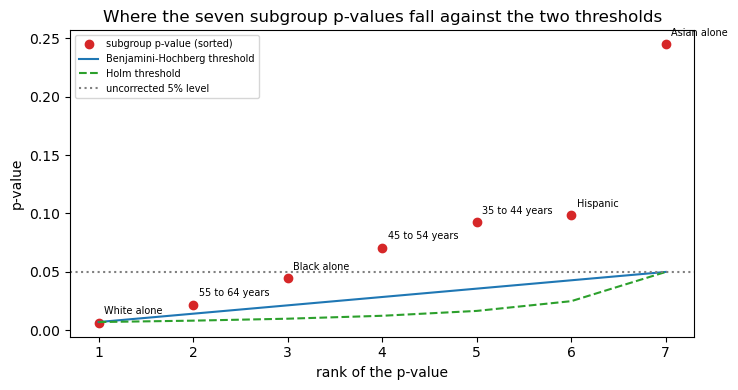

In [6]:
"""Holm and Benjamini-Hochberg over the seven pre-specified subgroup p-values, at the plan's level."""
fam = res.loc[FAMILY]
pvals = fam["p"].to_numpy(dtype=float)
holm = uncertainty.holm_bonferroni(pvals, alpha=ALPHA)
bh = uncertainty.benjamini_hochberg(pvals, alpha=ALPHA)
fam = fam.assign(raw=pvals <= ALPHA, holm=holm.rejected, bh=bh.rejected)
show = fam[["att", "lo", "hi", "p", "raw", "holm", "bh"]].round(4)
print(show.to_string())
print()
print(holm.render())
print(bh.render())
survivors_holm = list(fam.index[fam["holm"]])
survivors_bh = list(fam.index[fam["bh"]])
print(f"survive Holm: {survivors_holm if survivors_holm else 'none'}")
print(f"survive Benjamini-Hochberg: {survivors_bh if survivors_bh else 'none'}")

order = np.argsort(pvals)
rank = np.arange(1, len(pvals) + 1)
fig, ax = plt.subplots(figsize=(7.5, 4))
ax.plot(rank, pvals[order], "o", color="tab:red", label="subgroup p-value (sorted)")
ax.plot(rank, ALPHA * rank / len(pvals), "-", color="tab:blue", label="Benjamini-Hochberg threshold")
ax.plot(rank, ALPHA / (len(pvals) - rank + 1), "--", color="tab:green", label="Holm threshold")
ax.axhline(ALPHA, color="grey", linestyle=":", label="uncorrected 5% level")
for k, i in enumerate(order):
    ax.annotate(fam.index[i].split(",")[0].split(" (")[0], (rank[k], pvals[i]), textcoords="offset points", xytext=(4, 6), fontsize=7)
ax.set_xlabel("rank of the p-value")
ax.set_ylabel("p-value")
ax.set_title("Where the seven subgroup p-values fall against the two thresholds")
ax.legend(fontsize=7)
plt.tight_layout()
plt.show()

### The forest, beside C01's estimate

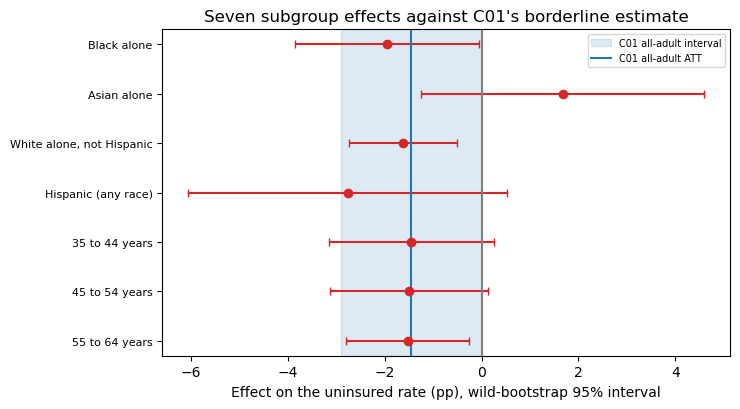

In [7]:
"""Each subgroup's ATT and wild-bootstrap interval, with C01's estimate and interval as the reference band."""
fig, ax = plt.subplots(figsize=(7.5, 4.2))
ypos = np.arange(len(FAMILY))[::-1]
for yv, name in zip(ypos, FAMILY):
    r = res.loc[name]
    if np.isnan(r["att"]):
        continue
    ax.errorbar(r["att"], yv, xerr=[[r["att"] - r["lo"]], [r["hi"] - r["att"]]], fmt="o", color="tab:red", capsize=3)
ax.axvspan(C01["lo"], C01["hi"], color="tab:blue", alpha=0.15, label="C01 all-adult interval")
ax.axvline(C01["att"], color="tab:blue", label="C01 all-adult ATT")
ax.axvline(0, color="grey")
ax.set_yticks(ypos)
ax.set_yticklabels(FAMILY, fontsize=8)
ax.set_xlabel("Effect on the uninsured rate (pp), wild-bootstrap 95% interval")
ax.set_title("Seven subgroup effects against C01's borderline estimate")
ax.legend(fontsize=7)
plt.tight_layout()
plt.show()

### Falsification 1: the subgroup pipeline reproduces C01

The all-adult series built here from table B27001 (three age bands, both sexes) is not C01's series, which came from B27010. If the pipeline measures the same quantity, the ATT is the same.

In [8]:
"""Falsification 1: the all-adult 35-64 ATT from B27001 equals C01's stored ATT."""
rep = res.loc[REFERENCE]
diff = float(rep["att"] - C01["att"])
REPRO_PASS = abs(diff) <= 0.001
print(f"all-adult ATT from B27001: {rep['att']:+.4f} pp; C01's stored ATT: {C01['att']:+.4f} pp; wild-bootstrap 95% interval from B27001 [{rep['lo']:+.3f}, {rep['hi']:+.3f}], C01 [{C01['lo']:+.3f}, {C01['hi']:+.3f}]")
print(f"FALSIFICATION: reproduction of C01 from table B27001 | statistic={abs(diff):.4f} | absolute difference in ATT, pp, threshold 0.001 | verdict={'PASS' if REPRO_PASS else 'FAIL'}")

all-adult ATT from B27001: -1.4530 pp; C01's stored ATT: -1.4530 pp; wild-bootstrap 95% interval from B27001 [-2.912, +0.006], C01 [-2.912, +0.006]
FALSIFICATION: reproduction of C01 from table B27001 | statistic=0.0000 | absolute difference in ATT, pp, threshold 0.001 | verdict=PASS


### Falsification 2: pre-trends, subgroup by subgroup

The event study of C01, with four leads and five lags and 2013 as the reference, is run in each estimable subgroup. The leads at relative years −4, −3 and −2 are tested jointly.

In [9]:
"""Falsification 2: joint test that the lead coefficients are zero, per subgroup."""
LEAD_PASS = {}
for name in [REFERENCE, *FAMILY]:
    if name not in fits:
        print(f"FALSIFICATION: pre-trend test, {name} | statistic=0 | subgroup not estimable, no test run | verdict=FAIL")
        LEAD_PASS[name] = False
        continue
    y, x, unit, time, _ = fits[name]
    panel = panels[name]
    adoption = np.where(panel["treated"].to_numpy() == 1, FIRST_TREATED_YEAR, np.nan)
    es = did.event_study_design(time, adoption, leads=4, lags=5, reference=-1)
    es_fit = did.twfe(y, es.matrix, unit, time, cluster=unit)
    labels = list(es.labels)
    idx = [labels.index(k) for k in (-4, -3, -2)]
    b = es_fit.coef[idx]
    v = es_fit.vcov[np.ix_(idx, idx)]
    f_stat = float(b @ np.linalg.solve(v, b)) / len(idx)
    p_joint = float(stats.f.sf(f_stat, len(idx), es_fit.n_clusters - 1))
    LEAD_PASS[name] = p_joint >= 0.10
    print(f"FALSIFICATION: pre-trend test, {name} | statistic={f_stat:.3f} | F({len(idx)},{es_fit.n_clusters - 1}) p={p_joint:.4f}, threshold 0.10 | verdict={'PASS' if LEAD_PASS[name] else 'FAIL'}")

FALSIFICATION: pre-trend test, All races, 35-64 | statistic=0.965 | F(3,34) p=0.4205, threshold 0.10 | verdict=PASS
FALSIFICATION: pre-trend test, Black alone | statistic=0.514 | F(3,30) p=0.6754, threshold 0.10 | verdict=PASS
FALSIFICATION: pre-trend test, Asian alone | statistic=0.438 | F(3,31) p=0.7276, threshold 0.10 | verdict=PASS
FALSIFICATION: pre-trend test, White alone, not Hispanic | statistic=2.029 | F(3,34) p=0.1282, threshold 0.10 | verdict=PASS
FALSIFICATION: pre-trend test, Hispanic (any race) | statistic=0.529 | F(3,34) p=0.6651, threshold 0.10 | verdict=PASS
FALSIFICATION: pre-trend test, 35 to 44 years | statistic=1.863 | F(3,34) p=0.1544, threshold 0.10 | verdict=PASS
FALSIFICATION: pre-trend test, 45 to 54 years | statistic=0.059 | F(3,34) p=0.9810, threshold 0.10 | verdict=PASS
FALSIFICATION: pre-trend test, 55 to 64 years | statistic=0.582 | F(3,34) p=0.6312, threshold 0.10 | verdict=PASS


### Falsification 3: the placebo outcome, per race group

The uninsured rate of people aged 65 and over is the outcome. Medicare covers this group in every state, so expansion should not move it. The age-band subgroups lie inside 35–64 and have no 65-and-over version.

In [10]:
"""Falsification 3: the ATT on the 65-and-over uninsured rate, same specification, per race group and for all races."""
PLACEBO_PASS = {}
for name in [REFERENCE, *RACE_TABLES]:
    if name not in fits:
        print(f"FALSIFICATION: placebo outcome, uninsured 65+, {name} | statistic=0 | subgroup not estimable, no test run | verdict=FAIL")
        PLACEBO_PASS[name] = False
        continue
    panel = panels[name]
    ok65 = panel.groupby("state")["rate65"].apply(lambda s: s.notna().all())
    p65 = panel[panel["state"].isin(ok65[ok65].index)]
    y65 = p65["rate65"].to_numpy()
    x65 = p65[["D"]].to_numpy(dtype=float)
    u65, t65 = p65["state"].to_numpy(), p65["year"].to_numpy()
    f65 = did.twfe(y65, x65, u65, t65, cluster=u65)
    b65 = did.wild_cluster_bootstrap(y65, x65, u65, t65, test_column=0, n_boot=N_BOOT, seed=SEED, cluster=u65)
    c65 = float(np.quantile(np.abs(b65.t_boot), 0.95))
    a65, s65 = float(f65.coef[0]), float(f65.se[0])
    lo65, hi65 = a65 - c65 * s65, a65 + c65 * s65
    PLACEBO_PASS[name] = lo65 <= 0.0 <= hi65
    dropped = panel["state"].nunique() - p65["state"].nunique()
    print(f"FALSIFICATION: placebo outcome, uninsured 65+, {name} | statistic={a65:.3f} | ATT in pp, wild-bootstrap 95% CI [{lo65:+.3f}, {hi65:+.3f}], p={b65.p_value:.3f}, {p65['state'].nunique()} states ({dropped} dropped for a missing 65+ cell) | verdict={'PASS' if PLACEBO_PASS[name] else 'FAIL'}")

FALSIFICATION: placebo outcome, uninsured 65+, All races, 35-64 | statistic=-0.050 | ATT in pp, wild-bootstrap 95% CI [-0.166, +0.065], p=0.384, 35 states (0 dropped for a missing 65+ cell) | verdict=PASS


FALSIFICATION: placebo outcome, uninsured 65+, Black alone | statistic=-0.055 | ATT in pp, wild-bootstrap 95% CI [-0.570, +0.460], p=0.834, 31 states (0 dropped for a missing 65+ cell) | verdict=PASS


FALSIFICATION: placebo outcome, uninsured 65+, Asian alone | statistic=2.855 | ATT in pp, wild-bootstrap 95% CI [+0.538, +5.171], p=0.016, 32 states (0 dropped for a missing 65+ cell) | verdict=FAIL


FALSIFICATION: placebo outcome, uninsured 65+, White alone, not Hispanic | statistic=0.012 | ATT in pp, wild-bootstrap 95% CI [-0.050, +0.074], p=0.711, 35 states (0 dropped for a missing 65+ cell) | verdict=PASS


FALSIFICATION: placebo outcome, uninsured 65+, Hispanic (any race) | statistic=0.326 | ATT in pp, wild-bootstrap 95% CI [-1.067, +1.719], p=0.644, 35 states (0 dropped for a missing 65+ cell) | verdict=PASS


### Results, in the units of the outcome

In [11]:
"""Results paragraph: every number is printed here from the computed objects."""
c01_banner()
n_est = int(kept[kept["subgroup"].isin(FAMILY)]["estimable"].sum())
n_raw, n_holm, n_bh = int(fam["raw"].sum()), int(fam["holm"].sum()), int(fam["bh"].sum())
print(f"{n_est} of {len(FAMILY)} pre-specified subgroups could be estimated. {n_raw} have an uncorrected bootstrap p of {ALPHA} or below; "
      f"{n_holm} remain after Holm (family-wise error) and {n_bh} after Benjamini-Hochberg (false discovery rate), both at the {int(ALPHA * 100)}% level.")
for name in FAMILY:
    r = res.loc[name]
    if np.isnan(r["att"]):
        print(f"- {name}: not estimable (fewer than {MIN_STATES} treated or control states pass the population floor); counted in the family with p = 1.")
        continue
    verdict = "distinguishable from zero after Holm" if fam.loc[name, "holm"] else (
        "distinguishable from zero after Benjamini-Hochberg only" if fam.loc[name, "bh"] else "not distinguishable from zero after correction")
    unc = "uncorrected interval excludes zero" if (r["hi"] < 0 or r["lo"] > 0) else "uncorrected interval contains zero"
    cred = "pre-trend passes" if LEAD_PASS[name] else "pre-trend fails"
    if name in PLACEBO_PASS:
        cred += ", placebo passes" if PLACEBO_PASS[name] else ", placebo fails"
    identified = LEAD_PASS[name] and PLACEBO_PASS.get(name, True)
    cred += "" if identified else "; by the plan's rule this estimate is descriptive, not identified"
    print(f"- {name}: ATT {r['att']:+.2f} pp, wild-bootstrap 95% interval [{r['lo']:+.2f}, {r['hi']:+.2f}] pp, p = {r['p']:.3f} ({unc}); {verdict}; {cred}. "
          f"{int(r['n_treated'])} treated and {int(r['n_control'])} control states.")
print()
print("Power, in percentage points: the smallest effect each subgroup test could detect at 80% power, and the chance it would detect an effect as large as C01's.")
print(res.loc[FAMILY, ["mde80", "power_c01"]].rename(columns={"mde80": "min detectable (pp)", "power_c01": "power at C01's ATT"}).round(3).to_string())

C01 (read from its stored output, not re-run): ATT -1.453 pp, wild-bootstrap 95% interval [-2.912, +0.006], p = 0.051.
  Borderline and seed-sensitive: the 9,999-draw interval contains zero (upper end +0.006), while at 99,999 draws p runs 0.0474 to 0.0482 and the upper end -0.020 to -0.013 across three seeds.
7 of 7 pre-specified subgroups could be estimated. 3 have an uncorrected bootstrap p of 0.05 or below; 1 remain after Holm (family-wise error) and 1 after Benjamini-Hochberg (false discovery rate), both at the 5% level.
- Black alone: ATT -1.95 pp, wild-bootstrap 95% interval [-3.86, -0.05] pp, p = 0.045 (uncorrected interval excludes zero); not distinguishable from zero after correction; pre-trend passes, placebo passes. 22 treated and 9 control states.
- Asian alone: ATT +1.67 pp, wild-bootstrap 95% interval [-1.25, +4.60] pp, p = 0.245 (uncorrected interval contains zero); not distinguishable from zero after correction; pre-trend passes, placebo fails; by the plan's rule this e

### Added after the first run: not pre-specified (added after the first run, 2026-10-27)

The cell below was added after the stored results were seen. It does not replace the plan's primary result, which is the 9,999-draw table above. The correction compares each p-value
with a threshold, and a bootstrap p-value carries Monte Carlo noise, so the cell asks how near each p-value sits to its threshold and whether the decisions survive more draws.

In [12]:
"""not pre-specified (added after the first run, 2026-10-27): Monte Carlo noise in the subgroup p-values and the decisions at 99,999 draws."""
mc_se = np.sqrt(fam["p"] * (1 - fam["p"]) / N_BOOT)
holm_thr = ALPHA / (len(FAMILY) - np.arange(len(FAMILY)))
rank_of = fam["p"].rank(method="first").astype(int) - 1
thr = pd.Series(holm_thr[rank_of.to_numpy()], index=fam.index)
close = pd.DataFrame({"p": fam["p"], "mc_se": mc_se, "holm_threshold": thr, "distance_in_mc_se": (fam["p"] - thr) / mc_se})
print(close.round(4).to_string())
rows = []
for seed in (SEED, SEED + 1, SEED + 2):
    ps = []
    for name in FAMILY:
        y, x, unit, time, _ = fits[name]
        ps.append(did.wild_cluster_bootstrap(y, x, unit, time, test_column=0, n_boot=99_999, seed=seed, cluster=unit).p_value)
    ps = np.array(ps)
    h, b = uncertainty.holm_bonferroni(ps, alpha=ALPHA), uncertainty.benjamini_hochberg(ps, alpha=ALPHA)
    rows.append({"seed": seed, "raw": int((ps <= ALPHA).sum()), "holm": h.n_significant_corrected, "bh": b.n_significant_corrected,
                 "holm_survivors": [n for n, r in zip(FAMILY, h.rejected) if r], "p_min": ps.min()})
    print(f"seed {seed}: p = " + ", ".join(f"{p:.4f}" for p in ps))
seeds = pd.DataFrame(rows)
print(seeds.to_string(index=False))
same = all(r["holm_survivors"] == seeds.loc[0, "holm_survivors"] for r in rows)
print(f"At 99,999 draws the set that survives Holm is {'the same in every seed' if same else 'NOT the same in every seed'}: "
      + "; ".join(f"seed {r['seed']}: {r['holm_survivors'] if r['holm_survivors'] else 'none'}" for r in rows)
      + f". The stored 9,999-draw result ({survivors_holm if survivors_holm else 'none'} after Holm) remains the plan's primary result.")

                                p   mc_se  holm_threshold  distance_in_mc_se
subgroup                                                                    
Black alone                0.0448  0.0021          0.0100            16.8231
Asian alone                0.2447  0.0043          0.0500            45.2905
White alone, not Hispanic  0.0065  0.0008          0.0071            -0.7991
Hispanic (any race)        0.0986  0.0030          0.0250            24.6887
35 to 44 years             0.0928  0.0029          0.0167            26.2398
45 to 54 years             0.0707  0.0026          0.0125            22.7063
55 to 64 years             0.0221  0.0015          0.0083             9.3651


seed 20261022: p = 0.0416, 0.2429, 0.0057, 0.0994, 0.0905, 0.0667, 0.0202


seed 20261023: p = 0.0417, 0.2419, 0.0063, 0.0986, 0.0887, 0.0664, 0.0201


seed 20261024: p = 0.0420, 0.2427, 0.0055, 0.0986, 0.0881, 0.0660, 0.0202
    seed  raw  holm  bh              holm_survivors   p_min
20261022    3     1   1 [White alone, not Hispanic] 0.00565
20261023    3     1   1 [White alone, not Hispanic] 0.00626
20261024    3     1   1 [White alone, not Hispanic] 0.00554
At 99,999 draws the set that survives Holm is the same in every seed: seed 20261022: ['White alone, not Hispanic']; seed 20261023: ['White alone, not Hispanic']; seed 20261024: ['White alone, not Hispanic']. The stored 9,999-draw result (['White alone, not Hispanic'] after Holm) remains the plan's primary result.


## Limitations

- **The departure from the specification.** The subgroups are race and ethnicity and three age bands inside 35–64, from the ACS detail tables, not the broader age bands of the subject table the track names. The reasons are in the Data Provenance note. Age bands outside 35–64 are not examined.
- **C01's estimate is borderline, and every subgroup inherits that.** The reference interval's upper end is a hair from zero and its verdict moves with the number of bootstrap draws (printed above, from C01's stored output). A subgroup result can be no firmer than the average it splits.
- **Power.** The table above gives each subgroup's minimum detectable effect and its power to detect an effect as large as C01's. Where the power is low, a subgroup that does not clear the bar says the test could not tell; it does not say the effect is absent.
- **Thin cells and the drop rule.** A state enters a subgroup only if its subgroup population aged 35–64 reaches the plan's floor in every year. The counts kept and dropped are printed above. Smaller subgroups keep fewer states, and fewer clusters make the bootstrap interval wider and its p-value coarser.
- **Overlap and dependence.** A person belongs to one race group and one age band, and the Black and Asian groups include Hispanic people, so the seven tests are not independent. Holm's procedure holds regardless; Benjamini–Hochberg assumes independence or positive dependence, and is a looser guarantee here.
- **Not a test of differences between subgroups.** A subgroup that survives correction and one that does not are not thereby different from each other. The plan does not specify a test of equality across subgroups, and none is run.
- **Measurement.** State-level ACS margins of error enter the outcome as noise and are not modelled. 2020 is missing.
- **Carried from C01.** The 2014-cohort design, the contaminated groups (states that already had broad adult coverage or an early expansion option), and the comparison against the non-expansion states' own version of the ACA all carry over unchanged.
- **Departures from the plan.** The analysis did not depart from the pre-analysis plan's estimator, family, correction or falsification tests. One analysis was added that the plan did not specify, labelled "not pre-specified (added after the first run, 2026-10-27)" in its cell: the Monte Carlo noise in the subgroup p-values and the correction decisions at 99,999 draws under three seeds. It does not replace the plan's primary result.

## Key Takeaways

1. A subgroup analysis is a family of tests. The count that look distinguishable from zero before correction and the count that remain after it are both printed above, and the difference is the cost of asking seven questions instead of one.
2. Holm controls the chance of any false finding across the family; Benjamini–Hochberg controls the expected share of false findings among those reported. The second is looser, and the notebook prints both so the choice is visible.
3. A subgroup that does not clear the bar has an interval and a power, both printed. Read the interval in percentage points; "not distinguishable from zero" is a statement about the test, not about the people.
4. The subgroups inherit the borderline status of the estimate they split, and the notebook prints that status beside every use of it.

## Exercises

1. Add the sex split (males and females from table B27001) as two more subgroups. How does the family size change the Holm threshold of the smallest p-value, and which conclusion changes?
2. Replace the alpha of 0.05 with 0.10 for both procedures. Which subgroup changes status under Benjamini–Hochberg, and which under Holm?
3. Test whether the effect in one race group equals the effect in another, by stacking the two panels and interacting treatment with group. Why is that a different question from the one asked here?
4. Re-run the bootstrap for the smallest p-value at 99,999 draws under three seeds. Does the correction decision change?

## References

- Holm, S. (1979). A simple sequentially rejective multiple test procedure. *Scandinavian Journal of Statistics*, 6(2), 65–70.
- Benjamini, Y., and Hochberg, Y. (1995). Controlling the false discovery rate: a practical and powerful approach to multiple testing. *Journal of the Royal Statistical Society: Series B*, 57(1), 289–300.
- Benjamini, Y., and Yekutieli, D. (2001). The control of the false discovery rate in multiple testing under dependency. *Annals of Statistics*, 29(4), 1165–1188.
- Cameron, A. C., Gelbach, J. B., and Miller, D. L. (2008). Bootstrap-based improvements for inference with clustered errors. *Review of Economics and Statistics*, 90(3), 414–427.
- U.S. Census Bureau. American Community Survey 1-year detail table B27001 and its race and ethnicity iterations, variable documentation.
- KFF. *Status of State Action on the Medicaid Expansion Decision* (see `data/policy/medicaid/SOURCES.md`).